# Storm surge — Bathtub and GeoClaw comparison on AOS tiles

Compares the outputs of the two storm surge notebooks for the same forecast cycle, on the AOS zoom-14 tiles (~2 km),
the scale at which AOS shows its results. Both models compute on the same 15″ (~450 m) coastal cells; the cells are
grouped into tiles here. 
- **Tile flooded:** at least one of its coastal cells reaches the threshold.
- **Tile water depth:** maximum depth over its cells.
- **Tile probability:** share of the 51 members in which the tile is flooded.



## 0. Setup

Requires the outputs of `01_surge_bathtub.ipynb` and `02_surge_geoclaw.ipynb` in `outputs/bathtub/` and
`outputs/geoclaw/`.

In [12]:
# Environment: PROJ database, warnings and log messages off
import os
import sys
import logging
import warnings
from pathlib import Path

proj_dir = str(Path(sys.prefix) / "share" / "proj")
os.environ["PROJ_DATA"] = proj_dir
os.environ["PROJ_LIB"] = proj_dir

import pyproj
pyproj.datadir.set_data_dir(proj_dir)

warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)   # errors are still shown

In [13]:
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

CONFIG = {
    "storm_name": "MELISSA",
    "country_iso3": "JAM",
    "cycle_tag": "melissa_20251028_00z",
    "bufr_file": PROJECT / "data/bufr/20251028_00z_tf.bufr",
    "bathtub_dir": PROJECT / "outputs/bathtub",
    "geoclaw_dir": PROJECT / "outputs/geoclaw",
    "geoclaw_tag": "melissa_20251028_00z_solver60as",
    "output_dir": PROJECT / "outputs/comparison",
    "zoom_level": 14,                 # AOS tile grid
    "surge_thresholds_m": [0.5, 1.0, 2.0, 3.0],
    "agreement_threshold_m": 0.5,     # threshold used for the agreement maps
    "likely_probability": 0.5,        # "likely" = at least half of the members
}

OUT = CONFIG["output_dir"]
OUT.mkdir(parents=True, exist_ok=True)
TAG = CONFIG["cycle_tag"]
THR = CONFIG["agreement_threshold_m"]
LIKELY = CONFIG["likely_probability"]
MODELS = {"bt": "Bathtub", "gc": "GeoClaw"}
COLORS = {"Bathtub": "#E07B39", "GeoClaw": "#2A9D8F", "Both": "#264653"}

## 1. Results of both models, grouped into AOS tiles

The member files of both models are read and checked to be on the same cells. Each cell is assigned to its AOS tile
(Bing quadkey, the AOS `tile_id`).

In [14]:
def member_depths(folder, tag):
    """Water depth per cell (rows) and member (columns), from the member files of one model."""
    files = sorted(Path(folder, "members").glob(f"{tag}_member*.parquet"))
    return pd.concat([pd.read_parquet(f) for f in files]).pivot(index="point_id", columns="member", values="depth_m")

cells_bt = pd.read_parquet(CONFIG["bathtub_dir"] / f"{TAG}_coastal_points.parquet").set_index("point_id")
cells_gc = pd.read_parquet(CONFIG["geoclaw_dir"] / f"{CONFIG['geoclaw_tag']}_coastal_points.parquet").set_index("point_id")
assert cells_bt.index.equals(cells_gc.index), "The two models are not on the same cells"
assert np.allclose(cells_bt[["lon", "lat"]].values, cells_gc[["lon", "lat"]].values), "Cell coordinates differ"
cells = cells_bt[["lon", "lat"]]

depth = {
    "bt": member_depths(CONFIG["bathtub_dir"], TAG).reindex(cells.index).fillna(0.0),
    "gc": member_depths(CONFIG["geoclaw_dir"], CONFIG["geoclaw_tag"]).reindex(cells.index).fillna(0.0),
}
for k, d in depth.items():
    print(f"{MODELS[k]}: {d.shape[0]} cells x {d.shape[1]} members")

Bathtub: 2913 cells x 51 members
GeoClaw: 2913 cells x 51 members


In [15]:
# AOS tile (Bing quadkey) of each cell
ZOOM = CONFIG["zoom_level"]
N = 2 ** ZOOM

def tile_xy(lon, lat):
    x = np.floor((np.asarray(lon) + 180) / 360 * N).astype(int)
    y = np.floor((1 - np.arcsinh(np.tan(np.radians(np.asarray(lat)))) / np.pi) / 2 * N).astype(int)
    return x, y

def quadkey(x, y):
    return "".join(str(((x >> (ZOOM - i)) & 1) + 2 * ((y >> (ZOOM - i)) & 1)) for i in range(1, ZOOM + 1))

tx, ty = tile_xy(cells["lon"].values, cells["lat"].values)
tile_of_cell = np.array([quadkey(a, b) for a, b in zip(tx, ty)])

# Tile polygons
xy = pd.DataFrame({"x": tx, "y": ty}, index=tile_of_cell).groupby(level=0).first()
tiles = gpd.GeoDataFrame(
    {"coastal_cells": pd.Series(tile_of_cell).value_counts().reindex(xy.index).values},
    index=xy.index,
    geometry=shapely.box(xy["x"] / N * 360 - 180,
                         np.degrees(np.arctan(np.sinh(np.pi * (1 - 2 * (xy["y"] + 1) / N)))),
                         (xy["x"] + 1) / N * 360 - 180,
                         np.degrees(np.arctan(np.sinh(np.pi * (1 - 2 * xy["y"] / N))))),
    crs="EPSG:4326")
tiles.index.name = "tile_id"

# Per tile and model: control max depth, and probability of reaching each threshold
thresholds = CONFIG["surge_thresholds_m"]
for k, d in depth.items():
    tile_max = d.groupby(tile_of_cell).max()                       # (tiles x members), max depth in the tile
    tiles[f"{k}_control_m"] = tile_max[0].reindex(tiles.index).values
    for t in thresholds:
        tiles[f"{k}_p_ge_{t:g}m"] = (tile_max >= t).mean(axis=1).reindex(tiles.index).values

tile_km2 = tiles.to_crs(tiles.estimate_utm_crs()).area.values / 1e6
print(f"{len(tiles)} AOS tiles contain coastal cells (mean tile area {tile_km2.mean():.1f} km²)")

351 AOS tiles contain coastal cells (mean tile area 5.4 km²)


## 2. Summary table (AOS tiles)

In [16]:
rows = []
for t in thresholds:
    row = {"threshold": f">= {t:g} m"}
    for k, label in MODELS.items():
        ctrl = tiles[f"{k}_control_m"].values >= t
        p = tiles[f"{k}_p_ge_{t:g}m"].values
        row[f"{label} control tiles"] = int(ctrl.sum())
        row[f"{label} P>0"] = int((p > 0).sum())
        row[f"{label} P>=50%"] = int((p >= LIKELY).sum())
    rows.append(row)

table = pd.DataFrame(rows).set_index("threshold")
table = table[[f"{m} {c}" for c in ("control tiles", "P>0", "P>=50%") for m in MODELS.values()]]
print(f"Control max depth — Bathtub: {tiles['bt_control_m'].max():.2f} m | GeoClaw: {tiles['gc_control_m'].max():.2f} m")
table

Control max depth — Bathtub: 1.46 m | GeoClaw: 1.41 m


,Bathtub control tiles,GeoClaw control tiles,Bathtub P>0,GeoClaw P>0,Bathtub P>=50%,GeoClaw P>=50%
threshold,,,,,,
>= 0.5 m,22,7,63,45,19,6
>= 1 m,7,1,40,31,6,0
>= 2 m,0,0,14,9,0,0
>= 3 m,0,0,0,0,0,0


## 3. Control member — agreement per tile

In [17]:
from gigaspatial.handlers import AdminBoundaries
from climada.hazard import TCTracks
from climada_petals.hazard.tc_tracks_forecast import TCForecast

country = gpd.GeoSeries(
    [AdminBoundaries.create(country_code=CONFIG["country_iso3"]).to_geoms()[0]], crs="EPSG:4326")
parts = country.explode(index_parts=False)
x0, y0, x1, y1 = parts.iloc[int(np.argmax(parts.area))].bounds    # main island only

fc = TCForecast()
fc.read_one_bufr_tc(str(CONFIG["bufr_file"]))
ctrl = next(t for t in fc.data if t.name.upper() == CONFIG["storm_name"]
            and bool(t.attrs["is_ensemble"]) and not 1 <= int(t.attrs["ensemble_number"]) <= 50)
ctrl_tracks = TCTracks(data=[ctrl])
ctrl_tracks.equal_timestep(time_step_h=1)
track0 = ctrl_tracks.data[0]

LABELS = {"Both": "Both models", "Bathtub": "Bathtub only", "GeoClaw": "GeoClaw only"}

def agreement(flag_bt, flag_gc):
    """Category per tile: Both / Bathtub / GeoClaw / None."""
    return np.select([flag_bt & flag_gc, flag_bt, flag_gc], ["Both", "Bathtub", "GeoClaw"], "None")

def agreement_counts(cat):
    n = {LABELS[k]: int((cat == k).sum()) for k in ("Both", "Bathtub", "GeoClaw")}
    union = sum(n.values())
    n["Overlap (both / any)"] = f"{100 * n['Both models'] / union:.0f}%" if union else "-"
    return n

def agreement_map(ax, cat, title):
    country.plot(ax=ax, color="#eeeeee", edgecolor="#999999", linewidth=0.5)
    for k in ("Bathtub", "GeoClaw", "Both"):
        sel = tiles[cat == k]
        if len(sel):
            sel.plot(ax=ax, color=COLORS[k], edgecolor="white", linewidth=0.3)
    ax.plot(track0.lon, track0.lat, color="crimson", linewidth=1)
    ax.set_xlim(x0 - 0.1, x1 + 0.1)
    ax.set_ylim(y0 - 0.1, y1 + 0.1)
    ax.set_title(title, fontsize=10)
    ax.legend([Patch(color=COLORS[k]) for k in ("Both", "Bathtub", "GeoClaw")],
              [f"{LABELS[k]} ({(cat == k).sum()})" for k in ("Both", "Bathtub", "GeoClaw")],
              loc="lower left", fontsize=8)

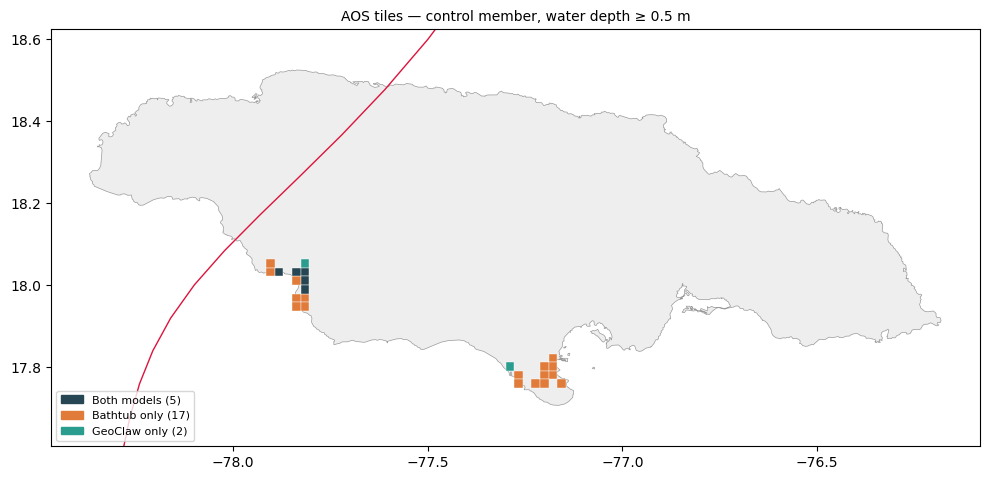

,"control, >= 0.5 m"
Both models,5
Bathtub only,17
GeoClaw only,2
Overlap (both / any),21%


In [18]:
cat_ctrl = agreement(tiles["bt_control_m"].values >= THR, tiles["gc_control_m"].values >= THR)

fig, ax = plt.subplots(figsize=(10, 5))
agreement_map(ax, cat_ctrl, f"AOS tiles — control member, water depth ≥ {THR:g} m")
plt.tight_layout()
plt.savefig(OUT / f"{TAG}_tiles_agreement_control_{THR:g}m.png", dpi=150)
plt.show()

pd.Series(agreement_counts(cat_ctrl), name=f"control, >= {THR:g} m").to_frame()

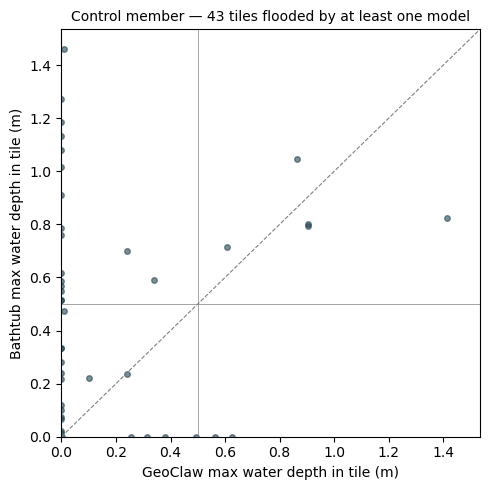

In [19]:
# Control member: maximum water depth per tile, Bathtub vs GeoClaw (tiles flooded by at least one model)
wet = (tiles["bt_control_m"] > 0) | (tiles["gc_control_m"] > 0)
vmax = max(tiles.loc[wet, ["bt_control_m", "gc_control_m"]].max().max(), 0.5) * 1.05

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(tiles.loc[wet, "gc_control_m"], tiles.loc[wet, "bt_control_m"], s=16, alpha=0.6, color=COLORS["Both"])
ax.plot([0, vmax], [0, vmax], color="grey", linewidth=0.8, linestyle="--")
ax.axhline(THR, color="grey", linewidth=0.5)
ax.axvline(THR, color="grey", linewidth=0.5)
ax.set_xlim(0, vmax)
ax.set_ylim(0, vmax)
ax.set_xlabel("GeoClaw max water depth in tile (m)")
ax.set_ylabel("Bathtub max water depth in tile (m)")
ax.set_title(f"Control member — {wet.sum()} tiles flooded by at least one model", fontsize=10)
plt.tight_layout()
plt.savefig(OUT / f"{TAG}_tiles_scatter_control_depth.png", dpi=150)
plt.show()

## 4. Ensemble — agreement on likely flooding per tile

A tile is "likely flooded" when it is flooded in at least half of the 51 members.

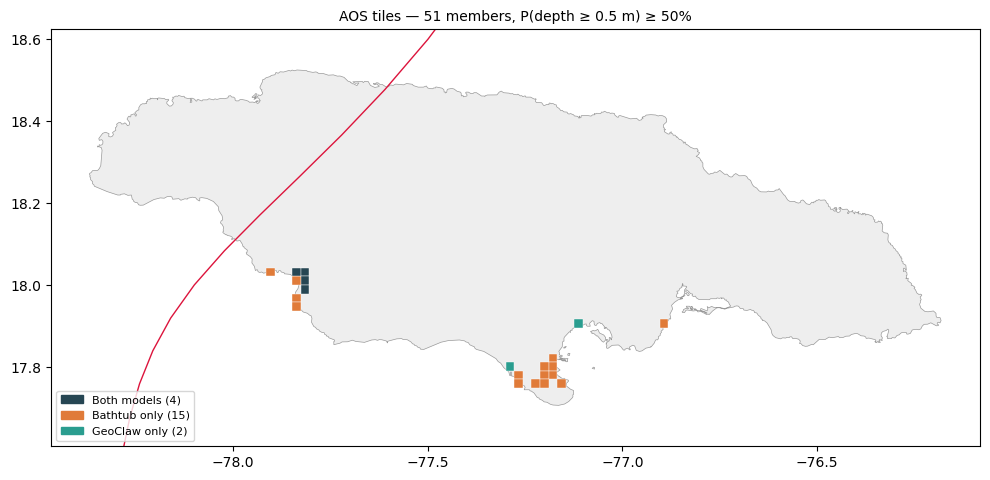

,"P >= 50%, >= 0.5 m"
Both models,4
Bathtub only,15
GeoClaw only,2
Overlap (both / any),19%


In [20]:
pcol = f"p_ge_{THR:g}m"
cat_ens = agreement(tiles[f"bt_{pcol}"].values >= LIKELY, tiles[f"gc_{pcol}"].values >= LIKELY)

fig, ax = plt.subplots(figsize=(10, 5))
agreement_map(ax, cat_ens, f"AOS tiles — 51 members, P(depth ≥ {THR:g} m) ≥ {LIKELY:.0%}")
plt.tight_layout()
plt.savefig(OUT / f"{TAG}_tiles_agreement_ensemble_{THR:g}m.png", dpi=150)
plt.show()

pd.Series(agreement_counts(cat_ens), name=f"P >= {LIKELY:.0%}, >= {THR:g} m").to_frame()

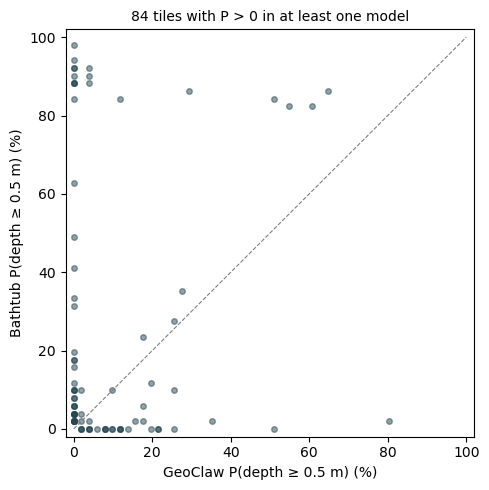

In [21]:
# Tile probability, Bathtub vs GeoClaw (tiles with P > 0 in at least one model)
hit = (tiles[f"bt_{pcol}"] > 0) | (tiles[f"gc_{pcol}"] > 0)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(tiles.loc[hit, f"gc_{pcol}"] * 100, tiles.loc[hit, f"bt_{pcol}"] * 100, s=16, alpha=0.5, color=COLORS["Both"])
ax.plot([0, 100], [0, 100], color="grey", linewidth=0.8, linestyle="--")
ax.set_xlim(-2, 102)
ax.set_ylim(-2, 102)
ax.set_xlabel(f"GeoClaw P(depth ≥ {THR:g} m) (%)")
ax.set_ylabel(f"Bathtub P(depth ≥ {THR:g} m) (%)")
ax.set_title(f"{hit.sum()} tiles with P > 0 in at least one model", fontsize=10)
plt.tight_layout()
plt.savefig(OUT / f"{TAG}_tiles_scatter_probability_{THR:g}m.png", dpi=150)
plt.show()

## 5. Computing cost

Runtime measured on the same laptop (Apple M2, 8 cores, 8 GB). Downloads are excluded.

In [22]:
bt_t = pd.read_csv(CONFIG["bathtub_dir"] / f"{TAG}_timings.csv", index_col=0)["seconds"]
gc_runs = pd.read_csv(CONFIG["geoclaw_dir"] / f"{CONFIG['geoclaw_tag']}_runs.csv", parse_dates=["start", "end"])

bt_s = bt_t[["3_wind_to_cells", "4_surge_bathtub"]].sum()
gc_ens = gc_runs[gc_runs["member"] > 0]
gc_wall_h = (gc_ens["end"].max() - gc_ens["start"].min()).total_seconds() / 3600

cost = pd.DataFrame({
    "Bathtub": {
        "Members": 51,
        "Wall time, 51 members": f"{bt_s:.0f} s",
        "Time per member": f"{bt_s / 51:.1f} s",
        "Parallel runs": "not needed",
    },
    "GeoClaw": {
        "Members": 51,
        "Wall time, 51 members": f"{gc_wall_h:.1f} h (+ control {gc_runs.loc[gc_runs.member == 0, 'minutes'].iloc[0]:.0f} min)",
        "Time per member": f"{gc_ens['minutes'].mean():.0f} min (min {gc_ens['minutes'].min():.0f}, max {gc_ens['minutes'].max():.0f})",
        "Parallel runs": "4 x 2 cores",
    },
})
cost

,Bathtub,GeoClaw
Members,51,51
"Wall time, 51 members",49 s,8.9 h (+ control 23 min)
Time per member,1.0 s,"42 min (min 22, max 134)"
Parallel runs,not needed,4 x 2 cores


## 6. Outputs

In [23]:
tiles["agreement_control"] = cat_ctrl
tiles["agreement_ensemble"] = cat_ens
tiles.drop(columns="geometry").reset_index().to_parquet(OUT / f"{TAG}_tiles_comparison_{THR:g}m.parquet", index=False)
table.to_csv(OUT / f"{TAG}_tiles_summary_table.csv")
cost.to_csv(OUT / f"{TAG}_cost.csv")
print("Saved to", OUT)

Saved to /Users/nassimdekkar/unicef/stormsurge/outputs/comparison
